

## Seguimiento cuaderno 07


## Trabajo práctico integrador

**Camila Amendolia**

Documentos educativos.

In [3]:
import os
from pathlib import Path

import gradio as gr
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from langchain_chroma import Chroma
from langchain_community.document_loaders import PyPDFLoader
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_ollama import ChatOllama, OllamaEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter

load_dotenv(".env")
print("Librerías cargadas.")

Librerías cargadas.


.

## 2. Elegir un recorte que puedas controlar



In [4]:
# Definimos la carpeta donde están nuestros 3 PDFs de la DGCyE
CARPETA_DATOS = Path("../Datos") if Path("../Datos").exists() else Path("../datos")
ARCHIVOS_PDF = sorted(CARPETA_DATOS.glob("*.pdf"))

# Leemos los modelos configurados en el archivo .env (o usamos valores por defecto)
MODELO_GENERADOR = os.getenv("OLLAMA_MODEL", "granite4:latest")
MODELO_EMBEDDINGS = os.getenv("OLLAMA_EMBEDDING_MODEL", "bge-m3")

# Verificamos que haya archivos PDF presentes antes de continuar
if not ARCHIVOS_PDF:
    raise FileNotFoundError(
        "No encontré archivos PDF en la carpeta Datos/. "
        "Verificá que tus 3 documentos estén guardados ahí."
    )

print("Archivos encontrados:", [archivo.name for archivo in ARCHIVOS_PDF])
print("Modelo generador:", MODELO_GENERADOR)
print("Modelo de embeddings:", MODELO_EMBEDDINGS)

Archivos encontrados: ['Documento de apoyo n°5- La intensificación de las materias pendientes de aprobación y acreditación en base a la estructura curricular.pdf', 'DOCUMENTO DE APOYO N°6 Intensificación_Profundización.pdf', 'DPESEC-Documento de Apoyo Nro 10_RA.pdf']
Modelo generador: granite4:latest
Modelo de embeddings: bge-m3


## 3. Cargar y revisar antes de indexar

Primero cargamos el PDF completo porque `PyPDFLoader` entrega una lista de páginas. Después seleccionamos sólo el rango de interés mediante el metadato `page`. Este paso demora poco para este archivo, pero en un corpus grande conviene diseñar una estrategia de carga más selectiva.

**Predicción.** Antes de ejecutar: ¿cuántas páginas esperás recuperar? ¿Cuál creés que será más difícil de convertir a texto: una página de prosa o una con ilustración?

In [5]:
# 1. Cargamos los 3 PDFs completos desde ARCHIVOS_PDF
paginas_del_capitulo = []  # Conservamos el nombre de variable para no romper celdas posteriores

for ruta_pdf in ARCHIVOS_PDF:
    cargador = PyPDFLoader(str(ruta_pdf))
    paginas_del_pdf = cargador.load()
    
    # 2. Conservamos todas las páginas y guardamos el número de página impreso (1-based)
    for pagina in paginas_del_pdf:
        pagina.metadata["pagina_impresa"] = pagina.metadata["page"] + 1
        pagina.metadata["archivo"] = ruta_pdf.name
        paginas_del_capitulo.append(pagina)
        
    print(f"Cargado '{ruta_pdf.name}': {len(paginas_del_pdf)} páginas")

print("Total de páginas cargadas entre los 3 documentos:", len(paginas_del_capitulo))

# Comprobamos que se hayan cargado páginas y que la primera comience en página 1
assert len(paginas_del_capitulo) > 0
assert paginas_del_capitulo[0].metadata["pagina_impresa"] == 1

Cargado 'Documento de apoyo n°5- La intensificación de las materias pendientes de aprobación y acreditación en base a la estructura curricular.pdf': 34 páginas
Cargado 'DOCUMENTO DE APOYO N°6 Intensificación_Profundización.pdf': 20 páginas
Cargado 'DPESEC-Documento de Apoyo Nro 10_RA.pdf': 6 páginas
Total de páginas cargadas entre los 3 documentos: 60




## 4. Medir antes de decidir cómo cortar

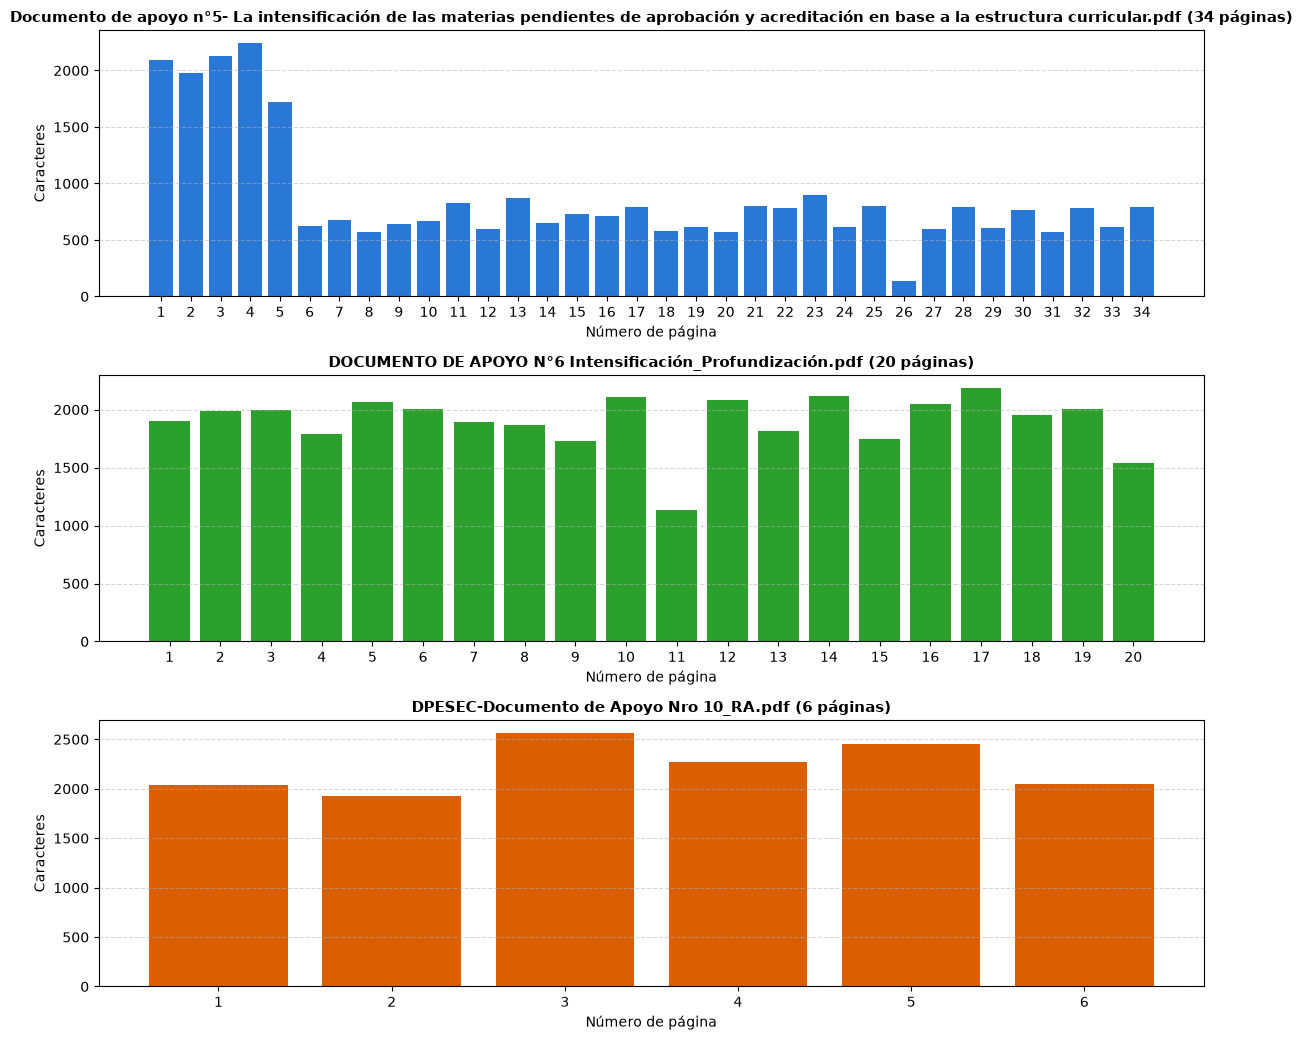

In [6]:
# Agrupamos las páginas por archivo
por_documento = {}
for pagina in paginas_del_capitulo:
    archivo = pagina.metadata["archivo"]
    por_documento.setdefault(archivo, []).append(pagina)

# Creamos un gráfico separado para cada documento (3 gráficos apilados)
fig, ejes = plt.subplots(len(por_documento), 1, figsize=(12, 3.5 * len(por_documento)))
colores = ["#2a78d6", "#2ca02c", "#d95f02"]

for i, (archivo, paginas) in enumerate(por_documento.items()):
    num_paginas = [p.metadata["page"] + 1 for p in paginas]
    caracteres = [len(p.page_content) for p in paginas]

    ejes[i].bar(num_paginas, caracteres, color=colores[i % len(colores)])
    ejes[i].set_title(f"{archivo} ({len(paginas)} páginas)", fontsize=11, fontweight="bold")
    ejes[i].set_xlabel("Número de página")
    ejes[i].set_ylabel("Caracteres")
    ejes[i].set_xticks(num_paginas)
    ejes[i].grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

## 5. Comparar dos formas de fragmentar


In [7]:
# Configuramos dos tamaños de corte distintos (en caracteres) para comparar su efecto
TAMANO_BREVE = 500
SOLAPAMIENTO_BREVE = 80
TAMANO_AMPLIO = 1100
SOLAPAMIENTO_AMPLIO = 180

# Creamos los dos divisores de texto
divisor_breve = RecursiveCharacterTextSplitter(
    chunk_size=TAMANO_BREVE,
    chunk_overlap=SOLAPAMIENTO_BREVE,
)
divisor_amplio = RecursiveCharacterTextSplitter(
    chunk_size=TAMANO_AMPLIO,
    chunk_overlap=SOLAPAMIENTO_AMPLIO,
)

# Cortamos las páginas del capítulo según cada estrategia
fragmentos_breves = divisor_breve.split_documents(paginas_del_capitulo)
fragmentos_amplios = divisor_amplio.split_documents(paginas_del_capitulo)

print("Fragmentos breves:", len(fragmentos_breves))
print("Fragmentos amplios:", len(fragmentos_amplios))
print("Primer fragmento breve:\n", fragmentos_breves[0].page_content[:500])

Fragmentos breves: 211
Fragmentos amplios: 105
Primer fragmento breve:
 Documento
de
Apoyo
N°5
La
intensificación
de
las
materias
pendientes
de
aprobación
y
acreditación
en
base
a
la
estructura
curricular
1.
La
intensificación
de
la
enseñanza
y
el
estudio
en
la
escuela
secundaria
El
presente
documento
tiene
como
propósito
orientar
a
los
equipos
directivos
y
docentes
en
la
implementación
de
la
intensificación
de
la
enseñanza
y
el
estudio
en
cada
una
de
las
materias
pendientes
de
aprobación
y
acreditación
del
Ciclo
Básico
y
del
Ciclo
Superior
Orientado,
según


In [8]:
pregunta_de_comparacion = "¿A qué estudiantes está dirigida la intensificación en julio y en agosto?"

# Conectamos con el modelo de embeddings local a través de Ollama
embeddings = OllamaEmbeddings(model=MODELO_EMBEDDINGS)

# Convertimos texto a listas de números (vectores) para verificar que el modelo responde
vector_pregunta = embeddings.embed_query(pregunta_de_comparacion)
vector_breve = embeddings.embed_query(fragmentos_breves[10].page_content)
vector_amplio = embeddings.embed_query(fragmentos_amplios[5].page_content)

# Verificamos que la longitud del vector sea idéntica sin importar el largo del texto
print("Dimensiones del vector de la pregunta:", len(vector_pregunta))
print("Dimensiones del vector breve:", len(vector_breve))
print("Dimensiones del vector amplio:", len(vector_amplio))
print("Los tres vectores deben tener la misma dimensión porque usan bge-m3.")

Dimensiones del vector de la pregunta: 1024
Dimensiones del vector breve: 1024
Dimensiones del vector amplio: 1024
Los tres vectores deben tener la misma dimensión porque usan bge-m3.


In [9]:
# Creamos dos colecciones temporales en memoria para comparar cada estrategia de corte
indice_breve = Chroma.from_documents(
    documents=fragmentos_breves,
    embedding=embeddings,
    collection_name="laboratorio_comparacion_breve",
)
indice_amplio = Chroma.from_documents(
    documents=fragmentos_amplios,
    embedding=embeddings,
    collection_name="laboratorio_comparacion_amplio",
)

# Buscamos el único fragmento más cercano (k=1) y tomamos el primer resultado ([0])
hallazgo_breve = indice_breve.similarity_search_with_score(
    query=pregunta_de_comparacion,
    k=1,
)[0]
hallazgo_amplio = indice_amplio.similarity_search_with_score(
    query=pregunta_de_comparacion,
    k=1,
)[0]

# Comparamos el archivo, página, distancia y texto recuperado por cada tamaño de fragmento
for nombre, hallazgo in [("Breve", hallazgo_breve), ("Amplio", hallazgo_amplio)]:
    documento, distancia = hallazgo
    archivo = documento.metadata.get("archivo", "Desconocido")
    print(f"\n{nombre} — {archivo} (página {documento.metadata['page'] + 1})")
    print("Distancia:", round(distancia, 3))
    print(documento.page_content)


Breve — DPESEC-Documento de Apoyo Nro 10_RA.pdf (página 1)
Distancia: 0.548
1.      La organización de la profundización e intensificación de la enseñanza y el estudio en julio y 
agosto 
De acuerdo a lo pautado en el Anexo II de la Resolución 1650/24 y en el Calendario de Actividades Docentes 
del presente ciclo lectivo, durante las semanas del 7 al 18 de julio y del 4 al 15 de agosto se implementarán 
períodos de intensificación de la enseñanza y el estudio para materias pendientes de aprobación y acreditación de

Amplio — DPESEC-Documento de Apoyo Nro 10_RA.pdf (página 1)
Distancia: 0.532
DOCUMENTO DE APOYO N° 10: Acerca de los períodos de Intensificación y 
Profundización de la enseñanza y el estudio de julio y agosto 
 
El presente documento se propone acompañar las acciones preparatorias, así como también la implementación 
de los períodos de intensificación y profundización de la enseñanza de julio y agosto, tanto de aquellos aspectos 
relativos a la organización institucional-

### Análisis de los fragmentos
Ambos respondieron correctamente

El fragmento breve  quedó cortado justo antes de la respuesta: Se interrumpió en "materias pendientes de aprobación y acreditación de", dejándose afuera que también incluye "años anteriores, en conjunto con períodos de intensificación y profundización de la enseñanza y el estudio para las materias del año en curso".

El fragmento amplio recuperó la oración completa (y además obtuvo una distancia menor: 0.532 frente a 0.548, lo que indica mayor cercanía semántica con tu pregunta).



## 6. Construir un índice persistente para el RAG



Se selecciona fragmentos amplios

In [10]:
CARPETA_INDICE = "../chroma_db_dgcye_ra"
NOMBRE_COLECCION = "regimen_academico_pba_bge_m3"

# 1. Conectamos con el índice persistente en disco
indice_rag = Chroma(
    collection_name=NOMBRE_COLECCION,
    embedding_function=embeddings,
    persist_directory=CARPETA_INDICE,
)

# 2. Si la colección ya contenía registros previos, la eliminamos para empezar limpios
if indice_rag.get(limit=1)["ids"]:
    indice_rag.delete_collection()
    indice_rag = Chroma(
        collection_name=NOMBRE_COLECCION,
        embedding_function=embeddings,
        persist_directory=CARPETA_INDICE,
    )

# 3. Asignamos un identificador explícito a cada fragmento (usamos fragmentos_amplios por mejor contexto)
identificadores = []
for numero in range(len(fragmentos_amplios)):
    identificadores.append(f"dgcye_fragmento_{numero}")

# 4. Guardamos los fragmentos en la base vectorial con sus identificadores
indice_rag.add_documents(documents=fragmentos_amplios, ids=identificadores)
print("Fragmentos indexados:", len(indice_rag.get()["ids"]))

Fragmentos indexados: 105


## 7. Recuperar evidencia antes de generar

Empezamos con una pregunta verificable: el capítulo señala que el español supera los 595 millones de hablantes. Mirá el contenido del fragmento, no sólo su distancia o su número de página.

In [11]:
pregunta = "¿Cómo se organizan los períodos de intensificación de julio y agosto y a quiénes están dirigidos?"
K = 3

# 1. Recuperamos los K fragmentos más cercanos semánticamente a la pregunta
hallazgos = indice_rag.similarity_search_with_score(query=pregunta, k=K)

contexto = ""
referencias = []

# 2. Construimos el bloque de texto con citas que servirá de evidencia para el modelo
for numero, hallazgo in enumerate(hallazgos, start=1):
    documento, distancia = hallazgo
    pagina_impresa = documento.metadata["page"] + 1
    nombre_archivo = documento.metadata["archivo"]
    referencia = f"{nombre_archivo}, página {pagina_impresa}"
    referencias.append(referencia)

    # Numeramos cada fragmento ([1], [2], [3]) para que el modelo pueda citar su fuente
    contexto += f"[{numero}] {referencia}\n{documento.page_content}\n\n"

    # Mostramos en pantalla qué fragmento recuperó y su distancia
    print(f"\n[{numero}] {referencia} — distancia {distancia:.3f}")
    print(documento.page_content[:500])

print("\nContexto completo enviado al modelo:\n", contexto)


[1] DPESEC-Documento de Apoyo Nro 10_RA.pdf, página 1 — distancia 0.605
DOCUMENTO DE APOYO N° 10: Acerca de los períodos de Intensificación y 
Profundización de la enseñanza y el estudio de julio y agosto 
 
El presente documento se propone acompañar las acciones preparatorias, así como también la implementación 
de los períodos de intensificación y profundización de la enseñanza de julio y agosto, tanto de aquellos aspectos 
relativos a la organización institucional-administrativa como a los aspectos pedagógico-didácticos. 
 
1.      La organización de la profundiz

[2] DPESEC-Documento de Apoyo Nro 10_RA.pdf, página 3 — distancia 0.753
posibilidad de implementarlos durante todo el año), permitiendo intensificar la enseñanza y el estudio con 
algunos estudiantes, y profundizar con otros. 
Ahora bien, resulta valioso preguntarse cuáles son las características específicas de estas instancias en el período 
de julio-agosto. Transcurrido ya medio año del ciclo lectivo, con una planificac

## 8. Generar sin ocultar la evidencia


In [12]:
# 1. Definimos la plantilla del prompt con rol de sistema (reglas) y rol humano (datos)
plantilla = ChatPromptTemplate.from_messages([
    (
        "system",
        "Respondé en español con una oración completa y sólo con la evidencia "
        "del contexto. Citá [1], [2] o [3] junto a cada afirmación. Si el dato "
        "no está en el contexto, respondé exactamente: No encuentro esa "
        "información en los documentos.",
    ),
    ("human", "Contexto:\n{contexto}\n\nPregunta: {pregunta}"),
])

# 2. Conectamos con el modelo de lenguaje (temperatura 0 para respuestas deterministas)
modelo = ChatOllama(model=MODELO_GENERADOR, temperature=0)

# 3. Encadenamos con el operador pipe '|': plantilla -> modelo -> texto limpio
cadena_rag = plantilla | modelo | StrOutputParser()

# 4. Invocamos la cadena enviando el contexto recuperado y la pregunta
respuesta = cadena_rag.invoke({"contexto": contexto, "pregunta": pregunta})

print("Respuesta:\n", respuesta)
print("\nFuentes que recibió el modelo:")
for referencia in referencias:
    print("-", referencia)

Respuesta:
 Los períodos de intensificación de julio y agosto están organizados para aquellos estudiantes con materias pendientes de aprobación y acreditación de años anteriores, en conjunto con períodos de intensificación y profundización de la enseñanza y el estudio para las materias del año en curso. Además, es posible realizar intensificación para los estudiantes con primera evaluación preliminar TEP y/o TED y en el período de agosto para quienes no tienen aprobado el primer examen correspondiente a la materia en cuestión. [1], [2], [3]

Fuentes que recibió el modelo:
- DPESEC-Documento de Apoyo Nro 10_RA.pdf, página 1
- DPESEC-Documento de Apoyo Nro 10_RA.pdf, página 3
- DPESEC-Documento de Apoyo Nro 10_RA.pdf, página 1


## 9. Laboratorio de fallas


In [13]:
# Lista de preguntas para probar aciertos, límites y abstenciones del sistema sobre el Régimen Académico
casos_de_prueba = [
    "¿Cuántos momentos del año tienen el primer y el segundo grupo para aprender los saberes enseñados y las materias no aprobadas?", # Debería encontrarlo en Doc 6
    "¿Cómo se organiza el modelo 4", # Debería encontrarlo en Doc 5
    "¿En qué semanas de julio y agosto se implementan los períodos de intensificación?", # Debería encontrarlo en Doc 10
    "¿Cuál es el salario básico de un docente de escuela secundaria en la Provincia de Buenos Aires?", # Abstención: no está en los documentos
]

for caso in casos_de_prueba:
    # 1. Recuperamos fragmentos para la pregunta actual
    hallazgos = indice_rag.similarity_search_with_score(query=caso, k=K)
    contexto_del_caso = ""

    # 2. Ensamblamos el contexto con el nombre del documento y página
    for numero, hallazgo in enumerate(hallazgos, start=1):
        documento, _ = hallazgo
        archivo = documento.metadata["archivo"]
        pagina = documento.metadata["page"] + 1
        contexto_del_caso += f"[{numero}] {archivo}, Página {pagina}\n{documento.page_content}\n\n"

    # 3. Generamos la respuesta con el modelo usando ese contexto
    respuesta_del_caso = cadena_rag.invoke(
        {"contexto": contexto_del_caso, "pregunta": caso}
    )

    # Extraemos archivo y página de los fragmentos para verificar la procedencia
    fuentes = [
        f"{hallazgo[0].metadata['archivo']} (p. {hallazgo[0].metadata['page'] + 1})"
        for hallazgo in hallazgos
    ]
    print("\nPregunta:", caso)
    print("Respuesta:", respuesta_del_caso)
    print("Fuentes recuperadas:", fuentes)


Pregunta: ¿Cuántos momentos del año tienen el primer y el segundo grupo para aprender los saberes enseñados y las materias no aprobadas?
Respuesta: El primer grupo tiene 5 momentos del año para aprender los saberes enseñados y las materias no aprobadas, mientras que el segundo grupo tiene 6 momentos del año para volver sobre lo enseñado en el año en curso. [1][2]
Fuentes recuperadas: ['DOCUMENTO DE APOYO N°6 Intensificación_Profundización.pdf (p. 12)', 'DOCUMENTO DE APOYO N°6 Intensificación_Profundización.pdf (p. 13)', 'DOCUMENTO DE APOYO N°6 Intensificación_Profundización.pdf (p. 11)']

Pregunta: ¿Cómo se organiza el modelo 4
Respuesta: El modelo 4 de intensificación de materias pendientes de aprobación y acreditación se organiza asistiendo a espacios de intensificación a contracurricular, finalizado el turno y/o los días de sábado. Allí, los estudiantes recibirán acompañamiento de docentes especialmente designadas para cumplimentar las propuestas de trabajo acordadas junto a 

### Actividad 2 — Diagnóstico

Elegí un caso y completá esta tabla en una celda Markdown propia.



| Pregunta | ¿Llegó evidencia pertinente? | ¿La respuesta la interpretó bien? | Diagnóstico | Cambio que probarías |
|---|---|---|---|---|
| ¿Cuántos momentos del año tienen el primer y el segundo grupo para aprender los saberes enseñados y las materias no aprobadas? | Sí (recuperó las páginas 11, 12 y 13 del *Documento de Apoyo N° 6*, donde figura el dato exacto). | No (invirtió las cifras: asignó 5 momentos al primer grupo y 6 al segundo, cuando en el texto original es 6 y 5 respectivamente). | **Generación** (la recuperación fue correcta, pero el modelo local `granite4:latest` cruzó los referentes entre dos fragmentos consecutivos `[1]` y `[2]` al sintetizar). | Ajustar la **redacción del prompt** de sistema indicando explícitamente que verifique a qué grupo corresponde cada cifra antes de responder y que no mezcle datos entre fragmentos distintos. |

## 10. Darle una interfaz al mismo RAG


In [14]:
def consultar(pregunta_usuario: str) -> tuple[str, str]:
    """Responde una pregunta y devuelve los fragmentos usados como evidencia.

    Args:
        pregunta_usuario: Consulta escrita en la interfaz.

    Returns:
        Respuesta del modelo y evidencia recuperada con páginas.
    """
    # Si la consulta está vacía o solo tiene espacios, respondemos sin llamar al modelo
    if not pregunta_usuario.strip():
        return "Escribí una pregunta.", "Todavía no se consultaron fuentes."

    # 1. Recuperamos los K fragmentos más cercanos a la consulta del usuario
    hallazgos = indice_rag.similarity_search_with_score(
        query=pregunta_usuario,
        k=K,
    )
    contexto_usuario = ""
    fuentes = ""

    # 2. Armamos dos versiones: una en texto plano para el LLM y otra en Markdown para la pantalla
    for numero, hallazgo in enumerate(hallazgos, start=1):
        documento, distancia = hallazgo
        pagina = documento.metadata["page"] + 1
        nombre_archivo = documento.metadata["archivo"]
        referencia = f"{nombre_archivo}, página {pagina}"

        # Contexto que se inyecta en el prompt del modelo
        contexto_usuario += f"[{numero}] {referencia}\n{documento.page_content}\n\n"

        # Formato visual con bloque de código para la interfaz web
        fuentes += f"**[{numero}] {referencia}** (distancia {distancia:.3f})\n\n"
        fuentes += f"```text\n{documento.page_content}\n```\n\n"

    # 3. El modelo redacta la respuesta basada exclusivamente en el contexto armado
    respuesta_usuario = cadena_rag.invoke(
        {"contexto": contexto_usuario, "pregunta": pregunta_usuario}
    )
    # Devolvemos la respuesta y los fragmentos por separado para mantener la transparencia
    return respuesta_usuario, fuentes


# Probamos la función con una pregunta sobre la normativa antes de conectar la interfaz gráfica
respuesta_de_prueba, fuentes_de_prueba = consultar(
    "¿En qué semanas de julio y agosto se implementan los períodos de intensificación?"
)
print(respuesta_de_prueba)
print(fuentes_de_prueba[:900])

En las semanas del 7 al 18 de julio y del 4 al 15 de agosto se implementan períodos de intensificación de la enseñanza y el estudio para materias pendientes de aprobación y acreditación de años anteriores, en conjunto con períodos de intensificación y profundización de la enseñanza y el estudio para las materias del año en curso. [1]
**[1] DPESEC-Documento de Apoyo Nro 10_RA.pdf, página 1** (distancia 0.528)

```text
DOCUMENTO DE APOYO N° 10: Acerca de los períodos de Intensificación y 
Profundización de la enseñanza y el estudio de julio y agosto 
 
El presente documento se propone acompañar las acciones preparatorias, así como también la implementación 
de los períodos de intensificación y profundización de la enseñanza de julio y agosto, tanto de aquellos aspectos 
relativos a la organización institucional-administrativa como a los aspectos pedagógico-didácticos. 
 
1.      La organización de la profundización e intensificación de la enseñanza y el estudio en julio y 
agosto 
De acu

In [15]:
# Conectamos la función 'consultar' a una interfaz web interactiva con Gradio
interfaz = gr.Interface(
    fn=consultar,
    inputs=gr.Textbox(
        label="Pregunta sobre el Régimen Académico (Resolución 1650/24 - DGCyE)",
        placeholder="Ej.: ¿Cómo se organizan los períodos de intensificación de julio y agosto?",
    ),
    outputs=[
        gr.Textbox(label="Respuesta"),
        gr.Markdown(label="Fragmentos recuperados y enviados al modelo"),
    ],
    title="RAG local: Consulta normativa DGCyE (Documentos de Apoyo N° 5, 6 y 10)",
    description=(
        "Asistente local sobre los Documentos de Apoyo de Intensificación y Profundización "
        "de la Enseñanza y el Estudio (Provincia de Buenos Aires). "
        "Verificá cada respuesta contra los fragmentos recuperados y los PDFs originales."
    ),
    examples=[
        ["¿En qué semanas de julio y agosto se implementan los períodos de intensificación?"],
        ["¿Cómo se organiza el modelo 4 de intensificación de materias pendientes?"],
        ["¿Cuál es el salario básico de un docente de escuela secundaria en la Provincia de Buenos Aires?"],
    ],
)

# Ejecutá esta última línea para abrir la interfaz. Detené la celda al terminar.
interfaz.launch()

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


## Transferencia al Trabajo Integrador 2



| Documento propio | Pregunta respondible | Página o sección esperada | ¿Qué recuperó? | ¿Qué interpretó el modelo? | Límite observado |
|---|---|---|---|---|---|
| Documento de apoyo n°5- La intensificación de las materias pendientes de aprobación y acreditación en base a la estructura curricular.pdf | ¿Cuántos modelos hay?| Página 3 (cuadro resumen con los 4 modelos) y Página 4 (mención explícita a "modelos 1, 2, 3 o 4"). | No recuperó el cuadro de la página 3; recuperó el fragmento de la página 4 donde se menciona la asignación de los modelos por parte del equipo directivo. | Respondió enumerando solo hasta el modelo 3, omitiendo el modelo 4 a pesar de que figuraba al final de la oración recuperada. | La extracción no se realiza del cuadro porque la información la identifica sólo en una oración |
| DOCUMENTO DE APOYO N°6 Intensificación_Profundización.pdf | ¿Cuántos momentos del año tienen el primer y el segundo grupo para aprender los saberes enseñados y las materias no aprobadas? | Páginas 11–13 (Organización de los tiempos y momentos de intensificación y profundización). | Recuperó las páginas 12, 13 y 11 del Documento de Apoyo N° 6. | Identificó los grupos y cifras (5 y 6 momentos), pero invirtió los valores (asignó 5 al primer grupo y 6 al segundo, cuando en el texto original es 6 y 5). | Se cruza la información. El corpus es pequeño y no tiene de donde comparar. |
|DPESEC-Documento de Apoyo Nro 10_RA.pdf |- ¿Qué significa CCA? - ¿Qué se debe consignar en el RITE del primer cuatrimestre? | Página 2 (elaboración y actualización del RITE - Primer Cuatrimestre). | Con la sigla aislada ("¿Qué significa CCA?") no recuperó el fragmento pertinente. Al reformular con contexto ("¿Qué se debe consignar en el RITE..."), recuperó exactamente la página 2. | 1) Ante "¿Qué significa CCA?", respondió "No encuentro esa información en los documentos.".2) Ante la consulta sobre el RITE, recuperó el texto donde figura "Continúa, Con Avances (CCA)" junto con AA y CSA. | Las siglas cortas y sin contexto (CCA) tienen baja densidad semántica para bge-m3; el modelo necesita palabras clave del entorno documental (RITE, primer cuatrimestre) para ubicar el fragmento. |

## Glosario

| Término | Qué significa en este laboratorio |
|---|---|
| **Documento** | Texto y metadatos de una página cargada con LangChain. |
| **Metadato** | Dato de procedencia, como el archivo y el índice de página. |
| **Fragmento** | Parte de una página que se puede representar y recuperar por separado. |
| **Embedding** | Vector que el modelo `bge-m3` usa para comparar significados. |
| **Chroma** | Base vectorial que conserva fragmentos, vectores y metadatos. |
| **k** | Cantidad de fragmentos recuperados para armar el contexto. |
| **RAG** | Recuperación de evidencia seguida de generación con ese contexto. |
| **Abstención** | Reconocimiento de que el contexto no alcanza para responder. |
| **Trazabilidad** | Posibilidad de volver desde una respuesta hasta el fragmento y la página original. |